#**Bureau of Transportation Statistics de Departamento de Transporte de Estados Unidos**
Integrantes

*   Alison Borda Sánchez
*   Carlos Esteban Mejía Gabanzo
*   Simón Jacobo Urbina Martínez
*   José Felipe Wagner Penagos

https://github.com/Simon-Urbina/vuelos-app-equipo4



**Pregunta de Negocio:**  ¿renovar los aviones más antiguos, reprogramar los vuelos de la tarde y la noche, o invertir en operación con mal tiempo?

Respuesta del equipo: Renovar los aviones más antiguos.

## Conocer el Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

zipfile.ZipFile("datos_vuelos.zip").extractall("datos")

vuelos      = pd.read_csv("datos/vuelos.csv")
clima       = pd.read_csv("datos/clima.csv")
aviones     = pd.read_csv("datos/aviones.csv")
aeropuertos = pd.read_csv("datos/aeropuertos.csv")
aerolineas  = pd.read_csv("datos/aerolineas.csv")
print("Tablas cargadas")

Tablas cargadas


In [5]:
tablas = {"vuelos": vuelos, "clima": clima, "aviones": aviones,
          "aeropuertos": aeropuertos, "aerolineas": aerolineas}
for nombre, t in tablas.items():
    print(f"{nombre:<12} {t.shape[0]:>8,} filas  {t.shape[1]:>2} columnas")
print(f"TOTAL        {sum(t.shape[0] for t in tablas.values()):>8,} filas")

vuelos        336,776 filas  19 columnas
clima          26,115 filas  15 columnas
aviones         3,322 filas   9 columnas
aeropuertos     1,458 filas   8 columnas
aerolineas         16 filas   2 columnas
TOTAL         367,687 filas


In [6]:
vuelos.head()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00


**Pregunta 1:** ¿Por qué vuelos tiene muchas más filas que aviones? ¿Qué columna los relaciona?

Respuesta: Vuelos tiene muchas más filas que aviones porque un avión puede hacer más de un vuelo. Y `'tailnum'` (matrícula) relaciona vuelos con aviones.

## Análisis Exploratorio EDA

count    327346.0
mean          6.9
std          44.6
min         -86.0
25%         -17.0
50%          -5.0
75%          14.0
max        1272.0
Name: arr_delay, dtype: float64


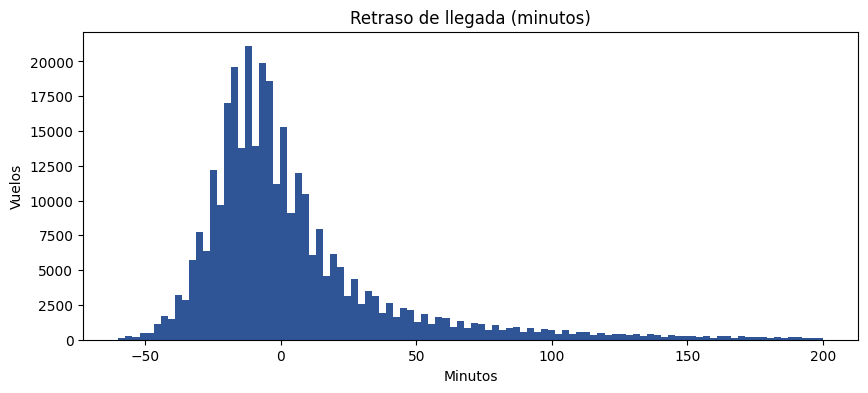

In [7]:
print(vuelos["arr_delay"].describe().round(1))
ax = vuelos["arr_delay"].plot(kind="hist", bins=100, range=(-60, 200), color="#2F5597",
figsize=(10, 4))
ax.set_title("Retraso de llegada (minutos)"); ax.set_xlabel("Minutos"); ax.set_ylabel("Vuelos")
plt.show()

Vuelos con dato de llegada: 327346
% que llega tarde: 24.5


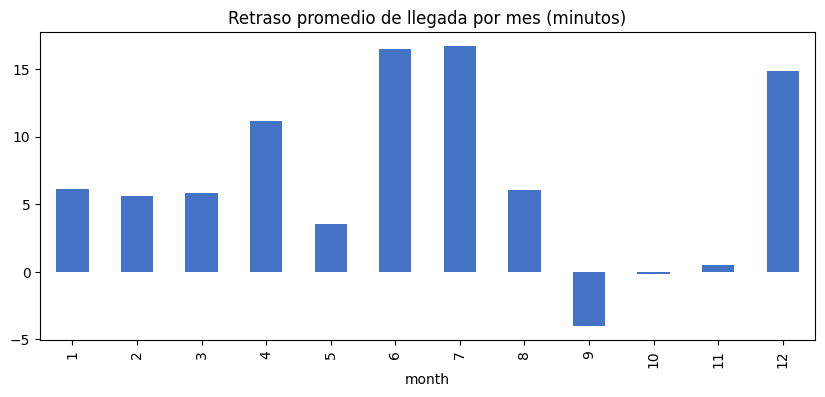

In [8]:
tarde = vuelos["arr_delay"] >= 15
print("Vuelos con dato de llegada:", vuelos["arr_delay"].notna().sum())
print("% que llega tarde:", round(tarde.sum() / vuelos["arr_delay"].notna().sum() * 100, 1))
por_mes = vuelos.groupby("month")["arr_delay"].mean()
por_mes.plot(kind="bar", color="#4472C4", figsize=(10, 4), title="Retraso promedio de llegada por mes (minutos)")
plt.show()

In [9]:
vuelos.isna().sum()

,0
year,0
month,0
day,0
dep_time,8255
sched_dep_time,0
dep_delay,8255
arr_time,8713
sched_arr_time,0
arr_delay,9430
carrier,0


In [10]:
clima[["temp", "humid", "wind_speed", "precip", "visib"]].describe().round(1)

,temp,humid,wind_speed,precip,visib
count,26114.0,26114.0,26111.0,26115.0,26115.0
mean,55.3,62.5,10.5,0.0,9.3
std,17.8,19.4,8.5,0.0,2.1
min,10.9,12.7,0.0,0.0,0.0
25%,39.9,47.0,6.9,0.0,10.0
50%,55.4,61.8,10.4,0.0,10.0
75%,70.0,78.8,13.8,0.0,10.0
max,100.0,100.0,1048.4,1.2,10.0


**Pregunta 2:** ¿Qué representan los vuelos sin hora de salida (dep_time nulo)? ¿Y los que tienen hora de salida pero no tienen retraso de llegada?

Respuesta: Los vuelos sin hora de salida son los vuelos cancelados, porque `'sched_dep_time'`es el tiempo para cuando estaba agendada la salida pero los 8255 vuelos que no salieron son los que tienen nulo en `'dep_time'`.

**Pregunta 3:** ¿Qué valor sospechoso aparece en la tabla de clima y por qué es imposible?

Respuesta: La velocidad del viento ('wind_speed') es el valor máximo sospechoso y es imposible que el viento vaya a 1048.4 millas/hora

## Limpieza

In [11]:
v = vuelos.dropna(subset=["dep_time", "arr_delay"]).copy()
print("Vuelos originales:", len(vuelos), "→ vuelos completados:", len(v))

Vuelos originales: 336776 → vuelos completados: 327346


In [12]:
llave = ["origin", "year", "month", "day", "hour"]
print("Horas repetidas:", clima.duplicated(llave).sum())
clima = clima.drop_duplicates(llave)
print("Registros de clima:", len(clima))

Horas repetidas: 3
Registros de clima: 26112


In [13]:
clima.loc[clima["wind_speed"] > 100, "wind_speed"] = np.nan
print((clima.isna().mean() * 100).round(1))
clima = clima.drop(columns=["wind_gust", "pressure", "dewp", "wind_dir", "time_hour"])
print("Columnas que quedan:", list(clima.columns))

origin         0.0
year           0.0
month          0.0
day            0.0
hour           0.0
temp           0.0
dewp           0.0
humid          0.0
wind_dir       1.8
wind_speed     0.0
wind_gust     79.6
precip         0.0
pressure      10.5
visib          0.0
time_hour      0.0
dtype: float64
Columnas que quedan: ['origin', 'year', 'month', 'day', 'hour', 'temp', 'humid', 'wind_speed', 'precip', 'visib']


In [14]:
v["vuelos_misma_hora"] = v.groupby(["origin", "year", "month", "day",
"hour"])["flight"].transform("count")
v["vuelos_misma_hora"].describe()

,vuelos_misma_hora
count,327346.000000
mean,20.048450
std,5.902452
min,1.000000
25%,17.000000
50%,20.000000
75%,24.000000
max,38.000000


In [15]:
df = (v.merge(clima, on=["origin", "year", "month", "day", "hour"], how="left")
       .merge(aviones[["tailnum", "year", "seats"]].rename(columns={"year":
"anio_fabricacion"}), on="tailnum", how="left")
       .merge(aerolineas, on="carrier", how="left")
       .merge(aeropuertos[["faa", "name"]].rename(columns={"faa": "dest", "name":
"nombre_destino"}), on="dest", how="left"))

print("Filas:", len(df))
print("Sin clima:", df["temp"].isna().sum())
print("Sin datos del avión:", df["anio_fabricacion"].isna().sum())
print("Destinos sin nombre:", df.loc[df["nombre_destino"].isna(), "dest"].unique())

Filas: 327346
Sin clima: 1544
Sin datos del avión: 53493
Destinos sin nombre: ['BQN' 'SJU' 'STT' 'PSE']


In [16]:
df.loc[df["anio_fabricacion"].isna(), "carrier"].value_counts().head()

,count
carrier,
MQ,24098
AA,22211
UA,1853
B6,1665
EV,1519


**Pregunta 4:** Más de 53.000 vuelos no tienen año de fabricación del avión. ¿A qué aerolíneas pertenecen y por qué no conviene rellenar ese dato con la mediana?

Respuesta: Las aerolíneas a las que pertenecen los más 53000 vuelos sin año de fabricación del avión son MQ, AA, UA, B6 y EV. No conviene rellenar ese dato con la mediana porque la desviasión es muy alta, ya que hay aviones que no se renuevan, es decir que son muy viejos, y afectan la mediana de los aviones más nuevos.

In [17]:
df["distancia_km"]   = (df["distance"] * 1.609).round(0)
df["temp_c"]         = ((df["temp"] - 32) * 5 / 9).round(1)
df["viento_kmh"]     = (df["wind_speed"] * 1.609).round(1)
df["lluvia_mm"]      = (df["precip"] * 25.4).round(1)
df["visibilidad_km"] = (df["visib"] * 1.609).round(1)
df["humedad"]        = df["humid"].round(0)
df[["distancia_km", "temp_c", "viento_kmh", "lluvia_mm", "visibilidad_km"]].describe().round(1)

,distancia_km,temp_c,viento_kmh,lluvia_mm,visibilidad_km
count,327346.0,325802.0,325741.0,325819.0,325819.0
mean,1686.8,13.9,17.8,0.1,15.0
std,1184.1,9.9,8.9,0.8,3.2
min,129.0,-11.7,0.0,0.0,0.0
25%,819.0,5.6,11.1,0.0,16.1
50%,1429.0,14.0,16.7,0.0,16.1
75%,2235.0,22.2,24.1,0.0,16.1
max,8018.0,37.8,68.5,30.7,16.1


In [18]:
df["fecha"] = pd.to_datetime(df[["year", "month", "day"]])
dias = {0: "1. Lunes", 1: "2. Martes", 2: "3. Miércoles", 3: "4. Jueves",
4: "5. Viernes", 5: "6. Sábado", 6: "7. Domingo"}
df["dia_semana"]  = df["fecha"].dt.dayofweek.map(dias)
df["edad_avion"]  = 2013 - df["anio_fabricacion"]
df["llueve"]      = (df["precip"] > 0).astype(int)
df["llego_tarde"] = (df["arr_delay"] >= 15).astype(int)
df["nombre_destino"] = df["nombre_destino"].fillna(df["dest"])
df[["fecha", "dia_semana", "edad_avion", "llueve", "llego_tarde"]].head()

,fecha,dia_semana,edad_avion,llueve,llego_tarde
0,2013-01-01,2. Martes,14.0,0,0
1,2013-01-01,2. Martes,15.0,0,1
2,2013-01-01,2. Martes,23.0,0,1
3,2013-01-01,2. Martes,1.0,0,0
4,2013-01-01,2. Martes,22.0,0,0


In [19]:
antes = len(df)
df = df.dropna(subset=["temp_c", "humedad", "visibilidad_km"])
print("Filas:", antes, "→", len(df))

Filas: 327346 → 325802


In [20]:
cortos = {"United Air Lines Inc.": "United", "JetBlue Airways": "JetBlue", "ExpressJet Airlines Inc.": "ExpressJet",
"Delta Air Lines Inc.": "Delta", "American Airlines Inc.": "American", "Envoy Air":
"Envoy",
"US Airways Inc.": "US Airways", "Endeavor Air Inc.": "Endeavor", "Southwest Airlines Co.": "Southwest"}
df["aerolinea"] = df["name"].map(cortos).fillna("Otras")
df["aerolinea"].value_counts()

,count
aerolinea,
United,57482
JetBlue,53714
ExpressJet,50863
Delta,47464
American,31820
Envoy,24935
US Airways,19767
Endeavor,17225
Southwest,11988


In [21]:
df["franja_horaria"] = pd.cut(df["hour"], bins=[0, 11, 15, 19, 23],
    labels=["1. Mañana (5-11 h)", "2. Mediodía (12-15 h)", "3. Tarde (16-19 h)", "4. Noche (2023 h)"])
df["rango_retraso"] = pd.cut(df["arr_delay"], bins=[-1000, -1, 14, 59, 179, 10000],
    labels=["1. Llegó antes", "2. 0 a 14 min", "3. 15 a 59 min", "4. 1 a 3 horas", "5. Más de 3 horas"])
print(df["franja_horaria"].value_counts().sort_index())
print(df["rango_retraso"].value_counts().sort_index())

franja_horaria
1. Mañana (5-11 h)       128077
2. Mediodía (12-15 h)     81043
3. Tarde (16-19 h)        86923
4. Noche (2023 h)         29759
Name: count, dtype: int64
rango_retraso
1. Llegó antes       188203
2. 0 a 14 min         57944
3. 15 a 59 min        51457
4. 1 a 3 horas        24314
5. Más de 3 horas      3884
Name: count, dtype: int64


In [22]:
final = df[["fecha", "month", "dia_semana", "hour", "franja_horaria", "aerolinea", "origin", "dest",
            "nombre_destino", "distancia_km", "edad_avion", "seats", "vuelos_misma_hora", "temp_c", "humedad",
            "viento_kmh", "lluvia_mm", "visibilidad_km", "llueve", "dep_delay", "arr_delay", "llego_tarde",
            "rango_retraso"]]
final = final.rename(columns={"month": "mes", "hour": "hora_programada", "origin": "origen", "dest": "destino",
                              "seats": "asientos", "dep_delay": "retraso_salida", "arr_delay": "retraso_llegada"})
final.to_csv("vuelos_limpio.csv", index=False)
final.to_csv("vuelos_limpio.csv.gz", index=False)
print(final.shape)
final.head()

(325802, 23)


,fecha,mes,dia_semana,hora_programada,franja_horaria,aerolinea,origen,destino,nombre_destino,distancia_km,...,temp_c,humedad,viento_kmh,lluvia_mm,visibilidad_km,llueve,retraso_salida,retraso_llegada,llego_tarde,rango_retraso
0,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),United,EWR,IAH,George Bush Intercontinental,2253.0,...,3.9,64.0,20.4,0.0,16.1,0,2.0,11.0,0,2. 0 a 14 min
1,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),United,LGA,IAH,George Bush Intercontinental,2278.0,...,4.4,55.0,24.1,0.0,16.1,0,4.0,20.0,1,3. 15 a 59 min
2,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),American,JFK,MIA,Miami Intl,1752.0,...,3.9,62.0,24.1,0.0,16.1,0,2.0,33.0,1,3. 15 a 59 min
3,2013-01-01,1,2. Martes,5,1. Mañana (5-11 h),JetBlue,JFK,BQN,BQN,2536.0,...,3.9,62.0,24.1,0.0,16.1,0,-1.0,-18.0,0,1. Llegó antes
4,2013-01-01,1,2. Martes,6,1. Mañana (5-11 h),Delta,LGA,ATL,Hartsfield Jackson Atlanta Intl,1226.0,...,4.4,55.0,25.9,0.0,16.1,0,-6.0,-25.0,0,1. Llegó antes


In [23]:
assert final.shape == (325802, 23), "Revise los pasos: el tamaño no coincide"
print("Archivos correctos. Descargue vuelos_limpio.csv y vuelos_limpio.csv.gz desde el panel Archivos.")

Archivos correctos. Descargue vuelos_limpio.csv y vuelos_limpio.csv.gz desde el panel Archivos.


**Pregunta 5:** Con lo que vieron hasta ahora, ¿mantienen su hipótesis inicial? Justifiquen en dos o tres líneas.

Respuesta: Por ahora, creemos que no vamos a mantener la hipótesis. La edad de la avión puede que sea lo que no pesa tanto sobre la llegada tardía, si no que mas bien es la hora de salida tardía, por lo que reprogramar los vuelos de la tarde y la noche sería la forma más efectiva de resolver el problema.